# Descriptive stats

100-m-Lauf `final`: gespeicherte Hauptmodellstichproben aus Notebook 08.
Arial · PNG/SVG · Tabellen als CSV · keine neuen Modellschätzungen.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ANAL").is_dir())
OUTPUT_DIR = PROJECT_DIR / "FIG" / "Descriptive stats"
sys.path[:0] = [str(PROJECT_DIR), str(OUTPUT_DIR)]
import descriptive_stats as ds

CELL_SIZE, RUN_NAME = 100, "final"
results = ds.analyse(PROJECT_DIR, CELL_SIZE, RUN_NAME, OUTPUT_DIR)
overview = results["sample"][["model", "rows", "units", "events"]].rename(columns={
    "model": "Modell", "rows": "Beobachtungen", "units": "Einheiten", "events": "Ereignisse"})
overview["Modell"] = overview.Modell.map(ds.MODELS)
display(ds.table(overview, digits=0))
if results["missing"]:
    print("Für Deskriptivwerte und Korrelationen fehlen lokal:", *results["missing"], sep="\n")

Modell,Beobachtungen,Einheiten,Ereignisse
Gründung,5.331.448,133.302,74.369
Überleben,4.112.838,168.326,63.416


Für Deskriptivwerte und Korrelationen fehlen lokal:
ANAL\data\100m\modelldaten\model_data_info.json
ANAL\data\100m\modelldaten\founding_frame.parquet
ANAL\data\100m\modelldaten\survival_frame.parquet


## Beschreibende Statistik

Originaleinheiten; Umfeld ohne eigene Zelle. Dichten nur bei Bevölkerung > 0.

In [2]:
for model, table in results["stats"].items():
    display(ds.table(table.drop(columns=["n", "Ausgeschlossen (P=0)"]), caption=ds.MODELS[model]))

## Korrelationen

Pearson in Modellskala, ohne Zeitkontrollen und p-Werte. Die Gründungsmatrix ergänzt den absoluten Autoumfeldbestand.

In [3]:
for model, matrix in results["correlations"].items():
    fig = ds.heatmap(matrix, OUTPUT_DIR, f"figure_{1 if model == 'founding' else 2}_korrelationen_{model}", triangular=True)
    display(fig)
    plt.close(fig)

## Vergleich mit Zentrennähe

Dieselben Modellzeilen, urban/regional: Straßenkilometer und Autofahrzeit. Gültige Paare je Maß stehen in der CSV.

In [4]:
for model, matrix in results["centres"].items():
    fig = ds.heatmap(matrix, OUTPUT_DIR, f"figure_{3 if model == 'founding' else 4}_zentren_{model}")
    display(fig)
    plt.close(fig)
if not results["centres"]:
    print("Zentrenvergleich benötigt zusätzlich die jährlichen nearest_infrastructure-Dateien.")

Zentrenvergleich benötigt zusätzlich die jährlichen nearest_infrastructure-Dateien.


## VIF

Gründung aus dem Export; Cox ohne Kalendertrend neu berechnet, sobald die Modelltabellen vorliegen. Bis dahin: exportierte Cox-Werte.

Modell,Variable,Gründung,Überleben
,Autobahnfahrzeit (log),"1,55","1,49"
,Bevölkerung Auto (log),"2,43","3,13"
,Bevölkerung Gehen (log),"3,86",–
,Bevölkerungsänderung (log),"1,01",–
,Eigenbestand (log),"1,38",–
,Eigenbestand fremd (log),–,"2,00"
,Eigenbestand gleich (log),–,"1,37"
,Eigenbevölkerung (log),"1,37","1,40"
,Keine Haltestelle,"2,65","2,03"
,Relativer Bestand Auto,"1,07",–


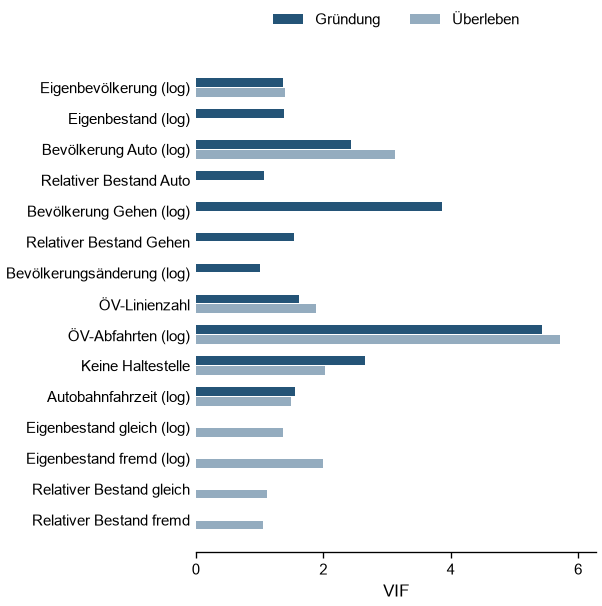

Tabellen, Abbildungen und kurzprotokoll.txt: C:\Users\leopo\Documents\CO2_Master_Code\CO2_Masterarbeit\FIG\Descriptive stats


In [5]:
display(ds.table(results["vif"].pivot(index="Variable", columns="Modell", values="VIF").reset_index(), digits=2))
fig = ds.vif_plot(results["vif"], OUTPUT_DIR)
display(fig)
plt.close(fig)
print("Tabellen, Abbildungen und kurzprotokoll.txt:", OUTPUT_DIR)

## Kaplan-Meier-Kurven und ?berlebensquoten

Die unadjustierten ?berlebensquoten beziehen sich auf das Alter seit Gr?ndung
in der exakten Cox-Modellstichprobe. Die Quartalsintervalle werden je Standort
zu einem Verlauf mit `Eintritt = min(start)`, `Ende = max(stop)` und dem letzten
Ereignisindikator zusammengefasst. Die Anzahl linkstrunkierter Standorte wird
anhand von `Eintritt > 0` gez?hlt und mit dem gespeicherten Hauptlauf gepr?ft.

Die Risikomenge bei Alter `t` enth?lt die Standorte mit `Eintritt < t <= Ende`.
Sp?t eintretende Standorte tragen ab ihrem beobachteten Eintritt bei. Die
?berlebensquoten nach 1, 3 und 5 Jahren entsprechen den Produktlimitwerten
nach 4, 12 und 20 Quartalen. Die Risikomengen beziehen sich jeweils auf den
Zeitpunkt unmittelbar vor einem dort m?glichen Austritt. Die Sch?tzung nutzt
den Parameter `entry` von `SurvfuncRight`. [Methodendokumentation](https://www.statsmodels.org/stable/generated/statsmodels.duration.survfunc.SurvfuncRight.html)

Graz wird anhand der Raster-Gemeinde-Zuordnung (`60101`) abgegrenzt.
Quoten werden bis zum Ende der durchgehenden Beobachtung ab Gr?ndung angegeben.
Fehlende zeitliche Unterst?tzung bleibt in der Quotentabelle ausgewiesen.
Die drei KM-Tabellen werden als CSV und die Kurven als PNG/SVG gespeichert.

In [ ]:
km = results["kaplan_meier"]
if not km["sample"].empty:
    display(ds.table(km["sample"][["Gruppe", "Standorte", "Linkstrunkiert", "Austritte", "Rechtszensiert"]],
                     digits=0, caption="Kaplan-Meier-Stichprobe"))
    rates = km["rates"].copy()
    for column in ["Jahre", "Risikomenge"]:
        rates[column] = rates[column].map(lambda value: ds.german(value, 0))
    display(ds.table(rates, digits=1, caption="?berlebensquoten nach 1, 3 und 5 Jahren"))
    if set(km["sample"].Gruppe) != set(ds.KM_GROUPS):
        print("F?r Graz und die ?brige Steiermark wird die Raster-Gemeinde-Zuordnung ben?tigt.")
if not km["curves"].empty:
    fig = ds.kaplan_meier_plot(km["curves"], OUTPUT_DIR)
    display(fig)
    plt.close(fig)
else:
    print("Kaplan-Meier ben?tigt die gespeicherten start/stop/event-Verl?ufe und Beobachtung ab Gr?ndung.")